# Figure S9D — PDB-disorder-monomer benchmark: ranking by MCC (top 40)

CAID3 disorder predictors ranked by Matthews correlation coefficient (MCC) at each method's Fmax threshold (this is the MCC reported by the CAID3 pipeline), on a stringent benchmark built only from structures of isolated, monomeric proteins. metapredict V1, V2 and V3 are coloured wherever they fall within the top 40.

**The benchmark.** For each CAID3 Disorder-PDB target, a residue is *ordered* if it is resolved with electron density in a PDB structure in which the protein is a lone chain (no partner, not a homo-oligomer), and *disordered* if it lies within such a monomeric construct but has no electron density. Every other residue is excluded. There are no DisProt annotations and no complex or homo-oligomer evidence, so this is a smaller, harder and more imbalanced set than Disorder-PDB. Labels come from `data/pdb_cache/monomer_labels.json` in the shared data directory, built by `data/pdb_cache_pipeline/run_pdb_coverage.py` (DisProt → SIFTS → PDBe).

**How it is made.** Same pooled per-residue scoring as Figure S3, with metapredict predicted by metapredict 3.1.0 (`data/metapredict_caid/`).

**Output:** `figures/figure_S09D.pdf`

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from caid3_panels import load_predictions, metric_panel, print_metapredict_ranks, rank_predictors
from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATASET = 'PDB-disorder-monomer'
TOP_N = 40

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# per-residue monomer labels: 1 disordered, 0 ordered, -1 excluded (sequence unused)
with open(shared_data_path('pdb_cache', 'monomer_labels.json')) as fh:
    reference = {tid: ('', np.asarray(labels, dtype=np.int8)) for tid, labels in json.load(fh).items()}

n_disordered = sum(int((lab == 1).sum()) for _, lab in reference.values())
n_ordered = sum(int((lab == 0).sum()) for _, lab in reference.values())
n_targets = sum(1 for _, lab in reference.values() if (lab >= 0).any())
print(f'{DATASET}: {n_ordered} ordered + {n_disordered} disordered residues over {n_targets} targets '
      f'({n_ordered / n_disordered:.1f} : 1)')

ranking = rank_predictors(reference, load_predictions(), dataset=DATASET)
print_metapredict_ranks(ranking)

PDB-disorder-monomer: 32904 ordered + 3807 disordered residues over 134 targets (8.6 : 1)


AUC   V1 0.693 (rank 43/66), V2 0.759 (rank 19/66), V3 0.791 (rank 11/66)
APS   V1 0.206 (rank 42/66), V2 0.255 (rank 21/66), V3 0.299 (rank 12/66)
FMAX  V1 0.284 (rank 46/66), V2 0.359 (rank 18/66), V3 0.412 (rank 9/66)
MCC   V1 0.185 (rank 46/66), V2 0.275 (rank 20/66), V3 0.340 (rank 10/66)


Wrote figures/figure_S09D.pdf


PosixPath('figures/figure_S09D.pdf')

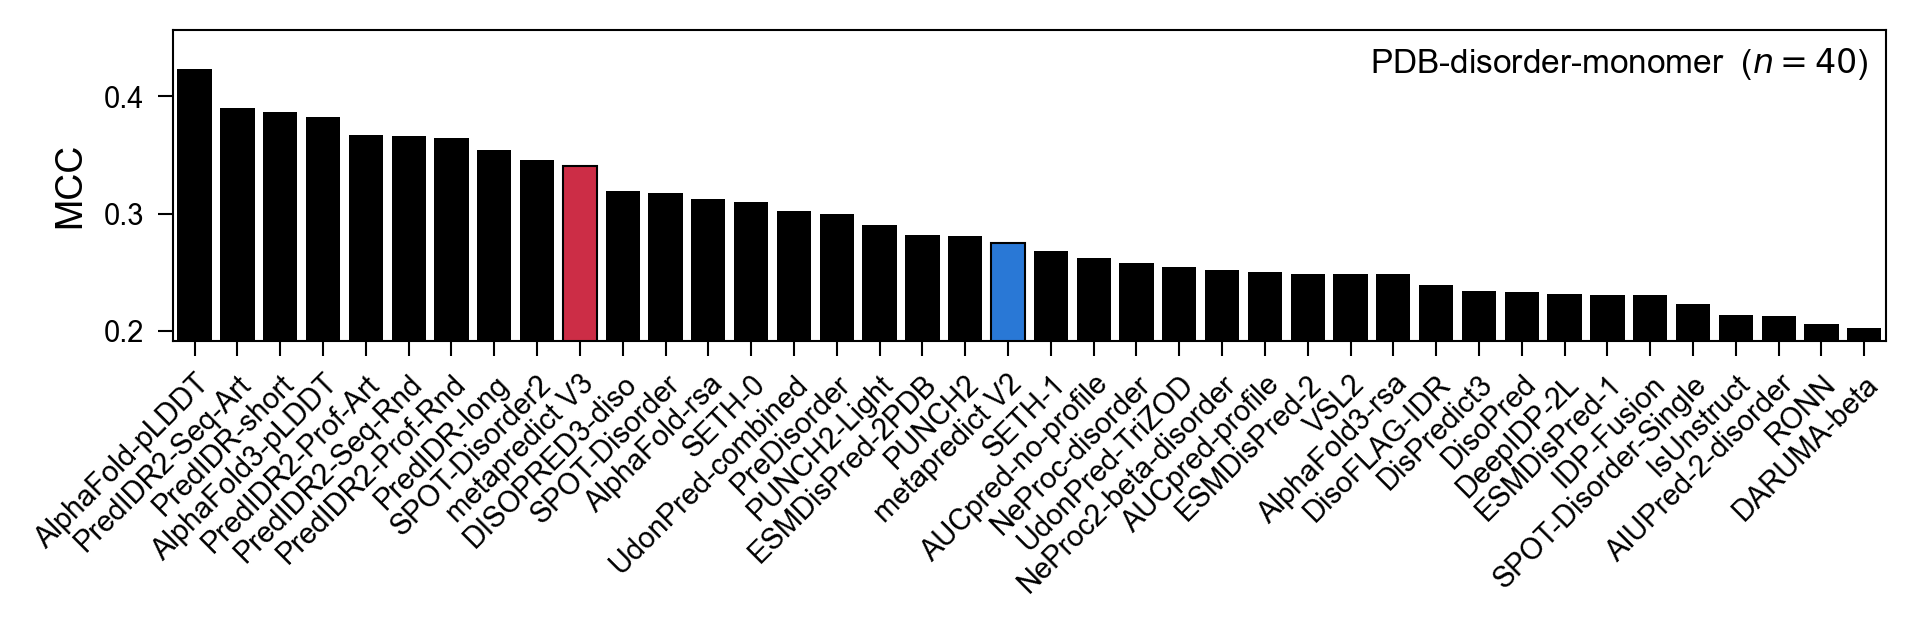

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.2), dpi=150)
metric_panel(ax, ranking, 'mcc', 'MCC', DATASET, top_n=TOP_N)
plt.tight_layout()
save_panel(fig, 'figure_S09D')